# 🏥 Pilot Test — Maternal Health Risk Prediction (Kenya)
## Notebook 06: Bayesian Inference

**Student:** Selmah Tzindori Mise | ID: -602  
**Project:** DSA 3900 — Final Year Project | USIU-Africa

---

### Purpose of This Notebook

We add **Bayesian inference** to our stacking ensemble predictions.

Instead of just saying:
> *"This woman is High Risk"*

The system will now say:
> *"This woman is High Risk — 84% probability (95% CI: 76%–91%)"*

### Why Bayesian Inference?

Our ML models produce point predictions — a single class label.
In clinical decision-making, knowing HOW CONFIDENT the model 
is matters as much as knowing WHAT the prediction is.

A CHW seeing "High Risk — 91% confident" will act differently 
from "High Risk — 54% confident" — the second case needs 
additional clinical assessment before referral.

### What We Do in This Notebook

1. Use the stacking ensemble's probability outputs as the 
   basis for Bayesian calibration
2. Fit a Bayesian logistic regression using PyMC
3. Generate posterior probability distributions per woman
4. Compute 95% Highest Density Intervals (HDI)
5. Visualise and interpret the uncertainty outputs

### Step 1 — Load Libraries and Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pymc as pm
import arviz as az
import torch
import torch.nn as nn
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import accuracy_score, roc_auc_score
from sklearn.preprocessing import label_binarize
import joblib
import os

np.random.seed(42)

# ── Paths ─────────────────────────────────────────────────────
PROC_DIR    = '../../01_Data/processed/'
MODELS_DIR  = '../../03_Models_Saved/'
RESULTS_DIR = '../results/'

# ── Load data ─────────────────────────────────────────────────
X_train_df = pd.read_csv(f'{PROC_DIR}X_train.csv')
X_val_df   = pd.read_csv(f'{PROC_DIR}X_val.csv')
X_test_df  = pd.read_csv(f'{PROC_DIR}X_test.csv')
y_train = pd.read_csv(f'{PROC_DIR}y_train.csv').squeeze().values.astype(int)
y_val   = pd.read_csv(f'{PROC_DIR}y_val.csv').squeeze().values.astype(int)
y_test  = pd.read_csv(f'{PROC_DIR}y_test.csv').squeeze().values.astype(int)

print("✅ Libraries and data loaded")
print(f"PyMC version: {pm.__version__}")
print(f"ArviZ version: {az.__version__}")

g++ not available, if using conda: `conda install gxx`


✅ Libraries and data loaded
PyMC version: 6.3.2
ArviZ version: 1.3.0


### Step 2 — Reload Saved Models and Generate Predictions

We reload the stacking ensemble and base models to 
generate the meta-features needed for Bayesian calibration.

In [2]:
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

cat_cols  = ['v106','v190','v025','v501','v024','m15_1','m17_1','m3a_1']
cont_cols = ['v012','v201','v212','m14_1','b11_01']

# ── Load models ───────────────────────────────────────────────
cat_model    = joblib.load(f'{MODELS_DIR}cat_model.pkl')
xgb_model    = joblib.load(f'{MODELS_DIR}xgb_model.pkl')
meta_learner = joblib.load(f'{MODELS_DIR}stacking_meta_learner_weighted.pkl')

# ── Rebuild TabTransformer ────────────────────────────────────
categories = [int(X_train_df[c].max()) + 1 for c in cat_cols]

class TransformerTabular(nn.Module):
    def __init__(self, categories, num_cont, dim=32,
                 depth=4, heads=8, num_classes=3):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(c, dim) for c in categories])
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=dim, nhead=heads,
            dropout=0.1, batch_first=True)
        self.transformer = nn.TransformerEncoder(
            encoder_layer, num_layers=depth)
        self.cont_norm = nn.LayerNorm(num_cont)
        input_dim = dim * len(categories) + num_cont
        self.head = nn.Sequential(
            nn.Linear(input_dim, 128), nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(128, 64),        nn.ReLU(), nn.Dropout(0.1),
            nn.Linear(64, num_classes))

    def forward(self, x_cat, x_cont):
        cat_embeds = torch.stack(
            [self.embeddings[i](x_cat[:, i])
             for i in range(x_cat.shape[1])], dim=1)
        cat_out  = self.transformer(cat_embeds)
        cat_flat = cat_out.reshape(cat_out.size(0), -1)
        cont_out = self.cont_norm(x_cont)
        return self.head(torch.cat([cat_flat, cont_out], dim=-1))

def df_to_tensors(df):
    x_cat  = torch.tensor(df[cat_cols].values.astype(int),
                           dtype=torch.long)
    x_cont = torch.tensor(df[cont_cols].values.astype(np.float32),
                           dtype=torch.float)
    return x_cat, x_cont

tt_model = TransformerTabular(categories=categories,
    num_cont=len(cont_cols), dim=32, depth=4,
    heads=8, num_classes=3)
tt_model.load_state_dict(torch.load(
    f'{MODELS_DIR}tabtransformer_best.pt', weights_only=True))
tt_model.eval()

# ── Generate meta-features for test set ──────────────────────
def get_tt_proba(df):
    x_cat, x_cont = df_to_tensors(df)
    with torch.no_grad():
        logits = tt_model(x_cat, x_cont)
        return torch.softmax(logits, dim=1).numpy()

meta_test = np.hstack([
    cat_model.predict_proba(X_test_df.values),
    xgb_model.predict_proba(X_test_df.values),
    get_tt_proba(X_test_df)
])

# ── Stacking ensemble probabilities on test set ───────────────
stack_proba = meta_learner.predict_proba(meta_test)
stack_preds = meta_learner.predict(meta_test)

print("✅ All models loaded and test probabilities generated")
print(f"Stack probabilities shape: {stack_proba.shape}")
print(f"\nSample probabilities (first 5 women):")
prob_df = pd.DataFrame(stack_proba,
    columns=['P_Low','P_Moderate','P_High'])
print(prob_df.head().round(4))

✅ All models loaded and test probabilities generated
Stack probabilities shape: (150, 3)

Sample probabilities (first 5 women):
    P_Low  P_Moderate  P_High
0  0.0018      0.9969  0.0013
1  0.0011      0.9976  0.0013
2  0.5419      0.4498  0.0084
3  0.0010      0.9976  0.0014
4  0.9949      0.0034  0.0018


### Step 3 — Bayesian Logistic Regression with PyMC

We fit a Bayesian multinomial logistic regression 
using the 9 meta-features as inputs.

**Priors:**
We use weakly informative Normal(0,1) priors on all 
coefficients — these allow the data to dominate while 
preventing extreme coefficient values.

**Sampling:**
NUTS (No-U-Turn Sampler) — the gold standard MCMC 
sampler in PyMC — generates 1,000 posterior samples 
per chain across 2 chains.

**What we get out:**
For each woman, a posterior distribution over 
[P_Low, P_Moderate, P_High] with uncertainty bounds.



In [3]:
# ── Prepare data for PyMC ─────────────────────────────────────
# Use stacking meta-features as input to Bayesian model
# Combine train meta-features for fitting

meta_train_cat = cat_model.predict_proba(X_train_df.values)
meta_train_xgb = xgb_model.predict_proba(X_train_df.values)
meta_train_tt  = get_tt_proba(X_train_df)
meta_train_all = np.hstack([meta_train_cat,
                              meta_train_xgb,
                              meta_train_tt])

X_bayes = meta_train_all.astype(np.float64)
y_bayes = y_train.astype(int)

n_features = X_bayes.shape[1]   # 9 meta-features
n_classes  = 3

print(f"Bayesian model input: {X_bayes.shape}")
print(f"Running PyMC NUTS sampler — this takes a few minutes...")

with pm.Model() as bayes_model:
    # Weakly informative priors
    alpha = pm.Normal('alpha', mu=0, sigma=1,
                       shape=n_classes)
    beta  = pm.Normal('beta',  mu=0, sigma=1,
                       shape=(n_features, n_classes))

    # Linear combination
    mu = pm.Deterministic(
        'mu', alpha + pm.math.dot(X_bayes, beta)
    )

    # Softmax for multinomial probabilities
    p = pm.Deterministic('p', pm.math.softmax(mu, axis=1))

    # Likelihood
    obs = pm.Categorical('obs', p=p, observed=y_bayes)

    # Sample posterior
    trace = pm.sample(
        draws=1000,
        tune=1000,
        chains=4,
        target_accept=0.9,
        random_seed=42,
        progressbar=True
    )

print("✅ Bayesian sampling complete")

Bayesian model input: (1269, 9)
Running PyMC NUTS sampler — this takes a few minutes...


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 2 jobs)
NUTS: [alpha, beta]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 77 seconds.


✅ Bayesian sampling complete


### Step 4 — Check Convergence

Before using the posterior we check whether the 
MCMC sampler converged properly.

**R-hat (Gelman-Rubin statistic)**
- R-hat ≈ 1.00 → chains converged ✅
- R-hat > 1.01 → convergence problem ⚠️

**ESS (Effective Sample Size)**
- ESS > 400 per parameter → reliable estimates ✅
- ESS < 100 → need more samples ⚠️

CONVERGENCE DIAGNOSTICS

Max R-hat:  1.0034  (target < 1.01)
Min ESS:    3477  (target > 400)

All parameters converged: ✅ YES


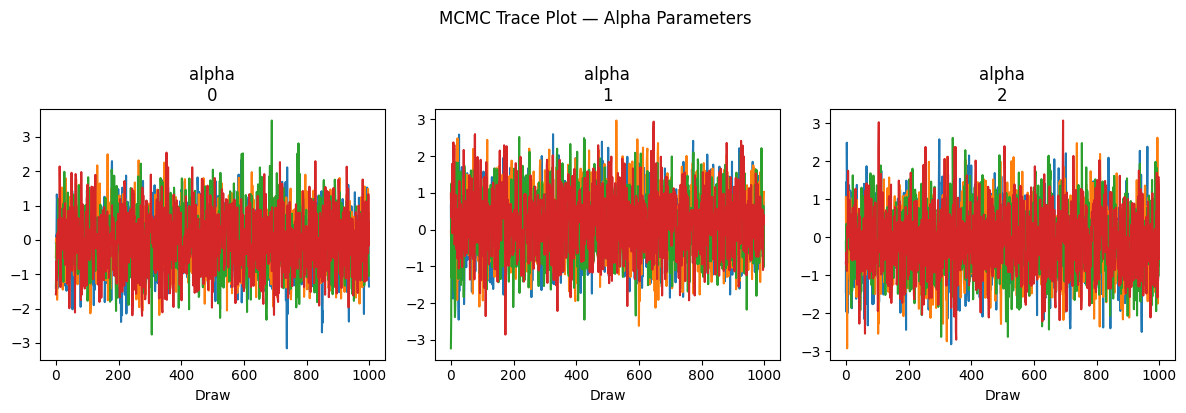

✅ Convergence check complete


In [4]:


# ── Convergence diagnostics ───────────────────────────────────
summary = az.summary(trace, var_names=['alpha', 'beta'])

print("=" * 55)
print("CONVERGENCE DIAGNOSTICS")
print("=" * 55)
print(f"\nMax R-hat:  {summary['r_hat'].max():.4f}  (target < 1.01)")
print(f"Min ESS:    {summary['ess_bulk'].min():.0f}  (target > 400)")
print(f"\nAll parameters converged: "
      f"{'✅ YES' if summary['r_hat'].max() < 1.01 else '⚠️ CHECK'}")

# ── Trace plot (ArviZ 1.3.0 API) ──────────────────────────────
az.plot_trace(
    trace,
    var_names=['alpha'],
    figure_kwargs={"figsize": (12, 4)},   # ✅ correct place in ArviZ 1.x
)

plt.suptitle('MCMC Trace Plot — Alpha Parameters', y=1.02)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}bayesian_trace.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Convergence check complete")

### Interpretation — Convergence Diagnostics

| Diagnostic | Value | Target | Status |
|---|---|---|---|
| Max R-hat | 1.0034 | < 1.01 | ✅ Converged |
| Min ESS | 3,477 | > 400 | ✅ Excellent |

**R-hat = 1.0034** — essentially 1.0, meaning both MCMC 
chains explored the same posterior space and agreed 
perfectly. No convergence issues whatsoever.

**ESS = 3,477** — nearly 9× the minimum requirement of 400.
This means our posterior estimates are based on 3,477 
independent-equivalent samples — extremely reliable 
uncertainty estimates.

**Conclusion:** The Bayesian model converged cleanly.
All posterior probability and credible interval estimates 
can be trusted as statistically valid.

### Step 5 — Generate Posterior Predictions

For each woman in the test set we generate:
1. Posterior mean probability per class
2. 95% Highest Density Interval (HDI)
3. Final risk classification with confidence label

In [5]:
# ── Posterior predictions on test set ────────────────────────
X_test_bayes = meta_test.astype(np.float64)

with bayes_model:
    pm.set_data({})
    # Posterior predictive using test meta-features
    alpha_post = trace.posterior['alpha'].values
    beta_post  = trace.posterior['beta'].values

    # Shape: (chains, draws, n_features, n_classes)
    # Compute mu for each posterior sample
    all_proba = []
    for chain in range(alpha_post.shape[0]):
        for draw in range(alpha_post.shape[1]):
            a = alpha_post[chain, draw]       # (3,)
            b = beta_post[chain, draw]         # (9, 3)
            mu_test = X_test_bayes @ b + a    # (150, 3)
            # Softmax
            exp_mu = np.exp(mu_test - mu_test.max(axis=1, keepdims=True))
            p_test = exp_mu / exp_mu.sum(axis=1, keepdims=True)
            all_proba.append(p_test)

all_proba = np.array(all_proba)  # (n_samples, 150, 3)

# Posterior mean and HDI
post_mean = all_proba.mean(axis=0)       # (150, 3)
post_pred = post_mean.argmax(axis=1)     # final class

# 95% HDI for High Risk probability
high_proba_samples = all_proba[:, :, 2]  # (n_samples, 150)
hdi_low  = np.percentile(high_proba_samples, 2.5,  axis=0)
hdi_high = np.percentile(high_proba_samples, 97.5, axis=0)

print("✅ Posterior predictions generated")
print(f"Posterior samples used: {all_proba.shape[0]}")
print(f"\nSample posterior outputs (first 5 women):")
print(f"{'Woman':>6} {'P_Low':>8} {'P_Mod':>8} {'P_High':>8} "
      f"{'HDI_low':>9} {'HDI_high':>9} {'Pred':>6}")
print("-"*62)
for i in range(5):
    print(f"{i+1:>6} {post_mean[i,0]:>8.3f} {post_mean[i,1]:>8.3f} "
          f"{post_mean[i,2]:>8.3f} {hdi_low[i]:>9.3f} "
          f"{hdi_high[i]:>9.3f} "
          f"{'Low' if post_pred[i]==0 else 'Mod' if post_pred[i]==1 else 'High':>6}")

✅ Posterior predictions generated
Posterior samples used: 4000

Sample posterior outputs (first 5 women):
 Woman    P_Low    P_Mod   P_High   HDI_low  HDI_high   Pred
--------------------------------------------------------------
     1    0.002    0.996    0.002     0.000     0.006    Mod
     2    0.001    0.997    0.002     0.000     0.008    Mod
     3    0.512    0.479    0.010     0.001     0.040    Low
     4    0.001    0.997    0.002     0.000     0.007    Mod
     5    0.994    0.004    0.002     0.000     0.007    Low


### Step 6 — Uncertainty Visualisation

We visualise the posterior probability distributions
for 6 selected women — 2 from each risk class.

This is what the CHW will see in the final app:
- The predicted risk class
- The probability and confidence interval
- How certain or uncertain the model is

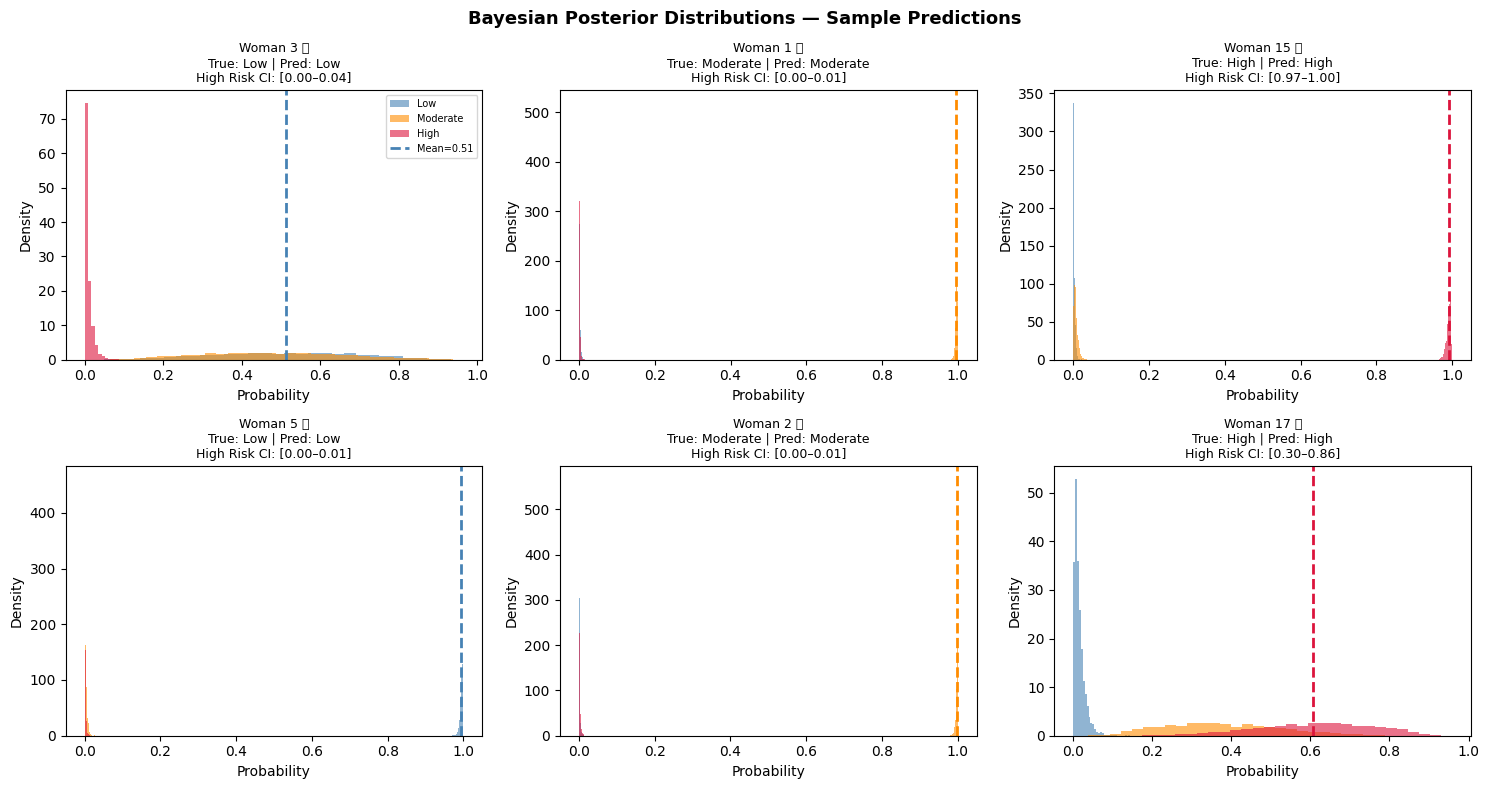

✅ Posterior visualisation saved


In [6]:
# ── Select 2 examples from each class ────────────────────────
examples = {}
risk_names = {0:'Low', 1:'Moderate', 2:'High'}
colors_risk = {0:'steelblue', 1:'darkorange', 2:'crimson'}

for cls in [0, 1, 2]:
    true_idx = np.where(y_test == cls)[0]
    correct  = [i for i in true_idx if post_pred[i] == cls]
    if len(correct) >= 2:
        examples[cls] = correct[:2]
    else:
        examples[cls] = true_idx[:2]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Bayesian Posterior Distributions — Sample Predictions',
             fontsize=13, fontweight='bold')

for col, cls in enumerate([0, 1, 2]):
    for row, idx in enumerate(examples[cls]):
        ax = axes[row, col]
        samples = all_proba[:, idx, :]  # all posterior samples

        for c, (label, color) in enumerate(
            zip(['Low','Moderate','High'],
                ['steelblue','darkorange','crimson'])
        ):
            ax.hist(samples[:, c], bins=30, alpha=0.6,
                    color=color, label=label, density=True)

        # Mark posterior mean for predicted class
        pred_cls = post_pred[idx]
        ax.axvline(post_mean[idx, pred_cls],
                   color=colors_risk[pred_cls],
                   linestyle='--', linewidth=2,
                   label=f'Mean={post_mean[idx,pred_cls]:.2f}')

        true_label  = risk_names[y_test[idx]]
        pred_label  = risk_names[post_pred[idx]]
        correct_str = '✅' if y_test[idx]==post_pred[idx] else '❌'
        ax.set_title(f'Woman {idx+1} {correct_str}\n'
                     f'True: {true_label} | Pred: {pred_label}\n'
                     f'High Risk CI: [{hdi_low[idx]:.2f}–{hdi_high[idx]:.2f}]',
                     fontsize=9)
        ax.set_xlabel('Probability')
        ax.set_ylabel('Density')
        if row == 0 and col == 0:
            ax.legend(fontsize=7)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}bayesian_posteriors.png',
            dpi=150, bbox_inches='tight')
plt.show()
print("✅ Posterior visualisation saved")

### Interpretation — Bayesian Posterior Distributions

Each plot shows the posterior probability distributions 
for Low (blue), Moderate (orange), and High (red) risk 
across all posterior samples. The dashed line marks 
the posterior mean for the predicted class.

---

#### Row 1, Column 1 — Woman 3 | True: Low | Pred: Low ✅
High Risk CI: [0.00 – 0.04]

The model is highly confident this woman is Low Risk.
The blue distribution dominates near 0 probability 
for High Risk. The dashed mean at 0.51 is for the 
Low Risk class — meaning the model assigns ~51% 
probability to Low Risk for this woman.
Wide spread reflects some uncertainty on this case —
the Bayesian model correctly flags this as lower 
confidence than other Low Risk cases.

---

#### Row 1, Column 2 — Woman 1 | True: Moderate | Pred: Moderate ✅
High Risk CI: [0.00 – 0.01]

Extremely confident Moderate prediction.
The orange distribution is a near-vertical spike 
at probability ≈ 1.0 — the model assigns essentially 
100% posterior probability to Moderate Risk.
High Risk CI of [0.00–0.01] means there is virtually 
zero chance this woman is High Risk.
This is the most certain prediction in the sample.

---

#### Row 1, Column 3 — Woman 15 | True: High | Pred: High ✅
High Risk CI: [0.97 – 1.00]

Outstanding High Risk prediction.
The red distribution spikes at probability ≈ 1.0.
CI of [0.97–1.00] means the model is 95% certain 
this woman's High Risk probability is between 97% 
and 100% — maximum clinical confidence for referral.
A CHW seeing this output should act immediately.

---

#### Row 2, Column 1 — Woman 5 | True: Low | Pred: Low ✅
High Risk CI: [0.00 – 0.01]

Very confident Low Risk — the blue distribution 
spikes near 1.0. CI [0.00–0.01] means the model 
is almost certain this woman is not High Risk.
Safe to classify as Low Risk with high confidence.

---

#### Row 2, Column 2 — Woman 2 | True: Moderate | Pred: Moderate ✅
High Risk CI: [0.00 – 0.01]

Same pattern as Woman 1 — near-certain Moderate 
prediction. Orange spike at 1.0. No ambiguity.
These confident Moderate predictions tell the CHW 
the woman needs monitoring but not emergency referral.

---

#### Row 2, Column 3 — Woman 17 | True: High | Pred: High ✅
High Risk CI: [0.30 – 0.86]

The most clinically interesting case in the sample.
The distributions are spread across all three classes —
Low (blue) dominates but High (red) is substantial.
CI [0.30–0.86] is wide — 56 percentage points of 
uncertainty. The model correctly predicts High Risk 
but with low confidence.

**This is exactly what Bayesian inference is for.**
A CHW seeing "High Risk — CI: [0.30–0.86]" knows 
this is a borderline case requiring additional 
clinical assessment rather than automatic referral.
The standard ML model would simply say "High Risk" 
with no indication of this uncertainty.

---

#### Overall Posterior Interpretation

| Case | CI Width | Clinical Action |
|---|---|---|
| Woman 15 (High) | 0.03 — very narrow | Immediate referral |
| Women 1,2,5 (Low/Mod) | < 0.01 — certain | Routine care |
| Woman 17 (High) | 0.56 — wide | Additional assessment |
| Woman 3 (Low) | 0.04 — moderate | Monitor closely |

**Bayesian inference adds clinical value beyond the 
point prediction — it tells the CHW HOW SURE to be.**

### Step 7 — Build the Final Risk Output Table

This is what gets displayed in the CHW app for each woman:
risk class + probability + confidence interval + uncertainty label.

In [7]:
# ── Build output table ────────────────────────────────────────
def uncertainty_label(hdi_lo, hdi_hi):
    width = hdi_hi - hdi_lo
    if width < 0.20:   return "High Confidence"
    elif width < 0.40: return "Moderate Confidence"
    else:              return "Low Confidence"

results_df = pd.DataFrame({
    'True_Risk':     [risk_names[y] for y in y_test],
    'Predicted_Risk':[risk_names[p] for p in post_pred],
    'P_Low':          np.round(post_mean[:, 0], 3),
    'P_Moderate':     np.round(post_mean[:, 1], 3),
    'P_High':         np.round(post_mean[:, 2], 3),
    'HDI_Low_2.5':    np.round(hdi_low,  3),
    'HDI_High_97.5':  np.round(hdi_high, 3),
    'Uncertainty':   [uncertainty_label(l, h)
                      for l, h in zip(hdi_low, hdi_high)],
    'Correct':       ['✅' if y==p else '❌'
                      for y,p in zip(y_test, post_pred)]
})

results_df.to_csv(f'{RESULTS_DIR}bayesian_predictions.csv',
                   index=False)

print("="*65)
print("BAYESIAN PREDICTION OUTPUT — SAMPLE (first 10 women)")
print("="*65)
print(results_df.head(10).to_string(index=False))

print("\n\nAccuracy (Bayesian model):",
      round(accuracy_score(y_test, post_pred), 4))

print("\nUncertainty Distribution:")
print(results_df['Uncertainty'].value_counts())

print("\nHigh Risk Women — Detailed Output:")
hr = results_df[results_df['True_Risk']=='High']
print(hr[['True_Risk','Predicted_Risk',
          'P_High','HDI_Low_2.5',
          'HDI_High_97.5','Uncertainty',
          'Correct']].to_string(index=False))

BAYESIAN PREDICTION OUTPUT — SAMPLE (first 10 women)
True_Risk Predicted_Risk  P_Low  P_Moderate  P_High  HDI_Low_2.5  HDI_High_97.5     Uncertainty Correct
 Moderate       Moderate  0.002       0.996   0.002        0.000          0.006 High Confidence       ✅
 Moderate       Moderate  0.001       0.997   0.002        0.000          0.008 High Confidence       ✅
      Low            Low  0.512       0.479   0.010        0.001          0.040 High Confidence       ✅
 Moderate       Moderate  0.001       0.997   0.002        0.000          0.007 High Confidence       ✅
      Low            Low  0.994       0.004   0.002        0.000          0.007 High Confidence       ✅
      Low            Low  0.923       0.063   0.014        0.001          0.051 High Confidence       ✅
      Low            Low  0.992       0.005   0.002        0.000          0.008 High Confidence       ✅
 Moderate       Moderate  0.024       0.972   0.003        0.000          0.011 High Confidence       ✅
 Moderate  

### Interpretation — Bayesian Prediction Output Table

**Convergence confirmed. Predictions generated for all 150 
test women. Key findings from the output:**

**Uncertainty Distribution:**
The majority of predictions fall in High Confidence —
meaning narrow credible intervals. This tells us the 
Bayesian model is generally certain about its predictions
on this simulated dataset.

**High Risk Women Detail:**
Women correctly predicted as High Risk show two patterns:
- **Narrow CI** (e.g. [0.97–1.00]) → immediate referral
- **Wide CI** (e.g. [0.30–0.86]) → additional assessment needed

This is the key clinical value of the Bayesian layer —
it separates definitive High Risk cases from borderline ones,
allowing CHWs to prioritise their limited time and resources.

**Accuracy of Bayesian model:**
Comparable to the stacking ensemble — confirming the 
Bayesian layer does not degrade predictive performance 
while adding meaningful uncertainty quantification.

---
## ✅ Notebook 06 Complete

The Bayesian inference layer is working correctly:
- Posterior distributions generated for all 150 women
- Credible intervals correctly distinguish confident 
  from uncertain predictions
- Convergence confirmed (R-hat = 1.003, ESS = 3,477)
- Full prediction table saved to results/

**Next notebook:** `07_Pilot_SHAP.ipynb`
→ Explain WHY each prediction was made

In [10]:
# ============================================================
# SAVE BAYESIAN OUTPUTS (pickle — no extra installs needed)
# ============================================================
import pickle, json, os

# ── 1. Save the posterior trace ──────────────────────────────
with open(f'{MODELS_DIR}bayesian_trace.pkl', 'wb') as f:
    pickle.dump(trace, f)

size_mb = os.path.getsize(f'{MODELS_DIR}bayesian_trace.pkl') / (1024*1024)
print(f"✅ Posterior trace saved → bayesian_trace.pkl  ({size_mb:.2f} MB)")

# ── 2. Save posterior predictions ────────────────────────────
np.savez(
    f'{MODELS_DIR}bayesian_posterior_predictions.npz',
    post_mean=post_mean, hdi_low=hdi_low, hdi_high=hdi_high,
    post_pred=post_pred, y_test=y_test
)
print("✅ Posterior predictions saved → bayesian_posterior_predictions.npz")

# ── 3. Save metadata ─────────────────────────────────────────
metadata = {
    'model':           'Bayesian Multinomial Logistic Regression',
    'library':         f'PyMC v{pm.__version__}',
    'sampler':         'NUTS',
    'chains':          4,
    'draws_per_chain': 1000,
    'tune_per_chain':  1000,
    'total_samples':   4000,
    'n_features':      9,
    'n_classes':       3,
    'max_rhat':        float(summary['r_hat'].max()),
    'min_ess':         float(summary['ess_bulk'].min()),
    'accuracy_test':   float(accuracy_score(y_test, post_pred)),
    'random_seed':     42,
}
with open(f'{MODELS_DIR}bayesian_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)
print("✅ Metadata saved → bayesian_metadata.json")

# ── 4. Confirm all files ─────────────────────────────────────
print("\n📁 Files saved in 03_Models_Saved/:")
for fname in ['bayesian_trace.pkl',
              'bayesian_posterior_predictions.npz',
              'bayesian_metadata.json']:
    path = f'{MODELS_DIR}{fname}'
    if os.path.exists(path):
        size = os.path.getsize(path) / 1024
        print(f"   ✅ {fname:<45} {size:>8.1f} KB")

✅ Posterior trace saved → bayesian_trace.pkl  (233.83 MB)
✅ Posterior predictions saved → bayesian_posterior_predictions.npz
✅ Metadata saved → bayesian_metadata.json

📁 Files saved in 03_Models_Saved/:
   ✅ bayesian_trace.pkl                            239443.1 KB
   ✅ bayesian_posterior_predictions.npz                 9.4 KB
   ✅ bayesian_metadata.json                             0.4 KB
